<a href="https://colab.research.google.com/github/YuYinCheong/Housing-Price-Analysis/blob/main/Housing_Price_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data preparation

In [ ]:
# Import tools and upload the CSV
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
sns.set_theme(style="whitegrid")

from google.colab import drive
from IPython.display import display
drive.mount("/content/drive")

# Load the original data.
file_path = (
    "/content/drive/MyDrive/UNF - University of North Florida/"
    "Fall 2026/Capstone/Housing.csv"
)

df_raw = pd.read_csv(file_path)

# Make a separate working copy.
df = df_raw.copy()

print("Rows and columns:", df.shape)
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rows and columns: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [ ]:
# Verify column names and inspect storage types.
expected_columns = [
    "price", "area", "bedrooms", "bathrooms", "stories",
    "mainroad", "guestroom", "basement", "hotwaterheating",
    "airconditioning", "parking", "prefarea", "furnishingstatus"
]

missing_columns = sorted(set(expected_columns) - set(df.columns))
extra_columns = sorted(set(df.columns) - set(expected_columns))

print("Missing expected columns:", missing_columns)
print("Unexpected columns:", extra_columns)

if missing_columns or extra_columns:
    raise ValueError("Review the column mismatch before continuing.")

df.info()

print("\nNumeric summary:")
display(df.describe().T.round(2))

print("\nText/category summary:")
display(df.describe(include=["object", "string", "category"]).T)

Missing expected columns: []
Unexpected columns: []
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
price,545.0,4766729.25,1870439.62,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,5150.54,2170.14,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,2.97,0.74,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,1.29,0.50,1.0,1.0,1.0,2.0,4.0
stories,545.0,1.81,0.87,1.0,1.0,2.0,2.0,4.0
parking,545.0,0.69,0.86,0.0,0.0,0.0,1.0,3.0



Text/category summary:


,count,unique,top,freq
mainroad,545,2,yes,468
guestroom,545,2,no,448
basement,545,2,no,354
hotwaterheating,545,2,no,520
airconditioning,545,2,no,373
prefarea,545,2,no,417
furnishingstatus,545,3,semi-furnished,227


In [ ]:
# Define variable groups and standardize text.
numeric_columns = [
    "price", "area", "bedrooms", "bathrooms", "stories", "parking"
]

yes_no_columns = [
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning", "prefarea"
]

text_columns = yes_no_columns + ["furnishingstatus"]

for column in text_columns:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace("", pd.NA)
    )

# Identify numeric conversion failures rather than hiding them.
conversion_failures = {}

for column in numeric_columns:
    converted = pd.to_numeric(df[column], errors="coerce")

    conversion_failures[column] = int(
        (df[column].notna() & converted.isna()).sum()
    )

    df[column] = converted

print("Values that could not be converted to numbers:")
display(pd.Series(conversion_failures, name="conversion_failures"))

Values that could not be converted to numbers:


,conversion_failures
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
parking,0


In [ ]:
# Missing values and exact duplicate rows.
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": 100 * df.isna().mean()
})

display(missing_summary)

# Count repeated rows beyond the first occurrence.
print("Exact duplicate rows:", df.duplicated().sum())

# If any exist, show every member of the duplicate groups.
duplicate_mask = df.duplicated(keep=False)

if duplicate_mask.any():
    display(df.loc[duplicate_mask])

,missing_count,missing_percent
price,0,0.0
area,0,0.0
bedrooms,0,0.0
bathrooms,0,0.0
stories,0,0.0
mainroad,0,0.0
guestroom,0,0.0
basement,0,0.0
hotwaterheating,0,0.0
airconditioning,0,0.0


Exact duplicate rows: 0


In [ ]:
# Flag values requiring investigation.
invalid = pd.DataFrame(index=df.index)

for column in numeric_columns:
    invalid[f"{column}_not_finite"] = (
        df[column].notna() & ~np.isfinite(df[column])
    )

# Positive measurements/counts expected for these fields.
for column in ["price", "area", "bedrooms", "bathrooms", "stories"]:
    invalid[f"{column}_nonpositive"] = df[column] <= 0

# Zero parking is valid.
invalid["parking_negative"] = df["parking"] < 0

# Counts should be whole numbers.
for column in ["bedrooms", "bathrooms", "stories", "parking"]:
    invalid[f"{column}_noninteger"] = (
        df[column].notna() & (df[column] % 1 != 0)
    )

for column in yes_no_columns:
    invalid[f"{column}_unexpected_label"] = (
        df[column].notna() & ~df[column].isin(["yes", "no"])
    )

furnishing_levels = ["unfurnished", "semi-furnished", "furnished"]

invalid["furnishing_unexpected_label"] = (
    df["furnishingstatus"].notna()
    & ~df["furnishingstatus"].isin(furnishing_levels)
)

print("Number of flags for each check:")
display(invalid.sum().astype(int))

flagged_rows = invalid.any(axis=1)

if flagged_rows.any():
    display(df.loc[flagged_rows])

# Stop before encoding if there are unresolved issues.
if df.isna().any().any() or flagged_rows.any():
    raise ValueError("Review missing or flagged values before continuing.")

print("Basic validation checks passed.")

Number of flags for each check:


,0
price_not_finite,0
area_not_finite,0
bedrooms_not_finite,0
bathrooms_not_finite,0
stories_not_finite,0
parking_not_finite,0
price_nonpositive,0
area_nonpositive,0
bedrooms_nonpositive,0
bathrooms_nonpositive,0


Basic validation checks passed.


In [ ]:
# Encode yes/no variables and create parking availability.
df_encoded = df.copy()

for column in yes_no_columns:
    df_encoded[column] = (
        df_encoded[column]
        .map({"no": 0, "yes": 1})
        .astype(int)
    )

# Preserve original parking count and add the agreed binary variable.
df_encoded["parking_available"] = (
    df_encoded["parking"] >= 1
).astype(int)

print("Parking recoding check:")
display(pd.crosstab(
    df_encoded["parking"],
    df_encoded["parking_available"],
    rownames=["Original parking count"],
    colnames=["Parking available"]
))

print("Parking availability counts:")
display(df_encoded["parking_available"].value_counts().sort_index())

Parking recoding check:


Parking available,0,1
Original parking count,,
0,299,0
1,0,126
2,0,108
3,0,12


Parking availability counts:


,count
parking_available,
0,299
1,246


In [ ]:
# Set the reference category and create furnishing dummies.
df_encoded["furnishingstatus"] = pd.Categorical(
    df_encoded["furnishingstatus"],
    categories=["unfurnished", "semi-furnished", "furnished"],
    ordered=False
)

df_encoded = pd.get_dummies(
    df_encoded,
    columns=["furnishingstatus"],
    prefix="furnishing",
    drop_first=True,
    dtype=int
)

# Simplify a column name for later formula-based modeling.
df_encoded = df_encoded.rename(columns={
    "furnishing_semi-furnished": "furnishing_semi"
})

display(df_encoded[
    ["furnishing_semi", "furnishing_furnished"]
].head())

,furnishing_semi,furnishing_furnished
0,0,1
1,0,1
2,1,0
3,0,1
4,0,1


In [ ]:
# Create the analysis table with the intended predictors.
numeric_predictors = ["area", "bedrooms", "bathrooms", "stories"]

binary_predictors = yes_no_columns + ["parking_available"]

furnishing_dummies = ["furnishing_semi", "furnishing_furnished"]

predictors = (
    numeric_predictors
    + binary_predictors
    + furnishing_dummies
)

# Exclude original parking count from this main analysis table.
df_analysis = df_encoded[["price"] + predictors].copy()

assert len(df_analysis) == len(df_raw)
assert not df_analysis.isna().any().any()
assert all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in df_analysis.dtypes
)

print("Analysis table shape:", df_analysis.shape)
display(df_analysis.head())
display(df_analysis.dtypes)

Analysis table shape: (545, 14)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,parking_available,furnishing_semi,furnishing_furnished
0,13300000,7420,4,2,3,1,0,0,0,1,1,1,0,1
1,12250000,8960,4,4,4,1,0,0,0,1,0,1,0,1
2,12250000,9960,3,2,2,1,0,1,0,0,1,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,1,1,0,1
4,11410000,7420,4,1,2,1,1,1,0,1,0,1,0,1


,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
mainroad,int64
guestroom,int64
basement,int64
hotwaterheating,int64
airconditioning,int64


# Exploratory data analysis (EDA)

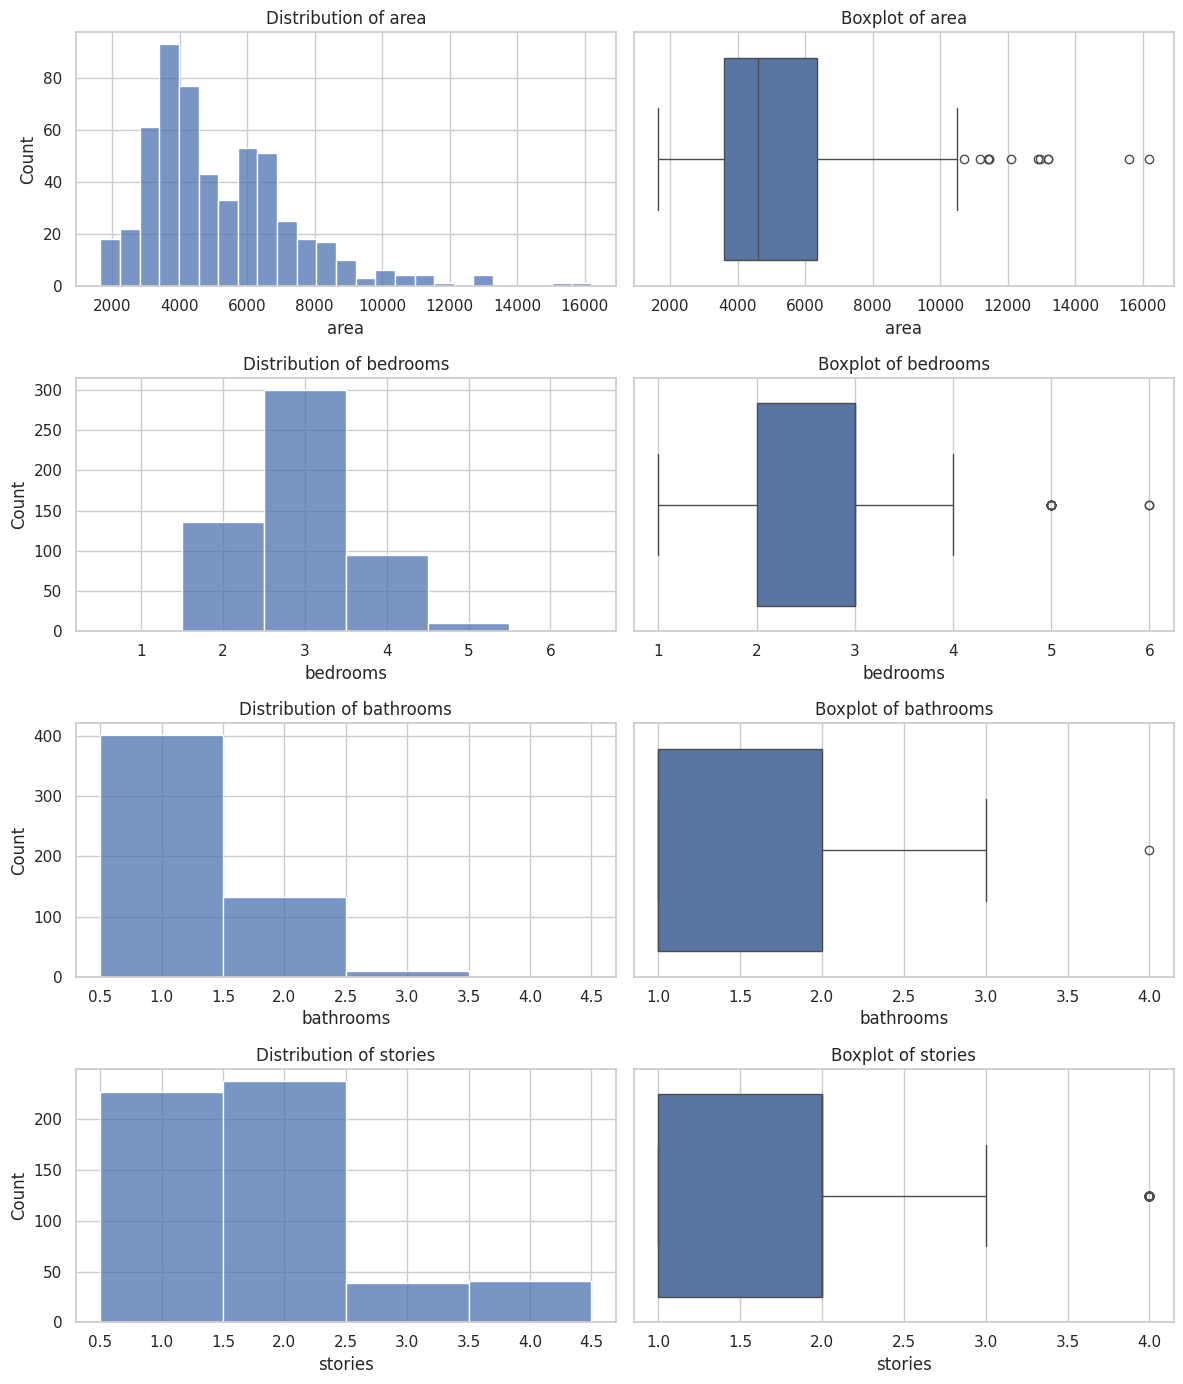

In [ ]:
# Cell 10: Examine numeric predictors on their original scales.
fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for row, column in enumerate(numeric_predictors):
    # Count variables need bars centered on whole numbers.
    if column == "area":
        sns.histplot(data=df, x=column, bins=25, ax=axes[row, 0])
    else:
        sns.histplot(data=df, x=column, discrete=True, ax=axes[row, 0])

    sns.boxplot(data=df, x=column, ax=axes[row, 1])

    axes[row, 0].set_title(f"Distribution of {column}")
    axes[row, 1].set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

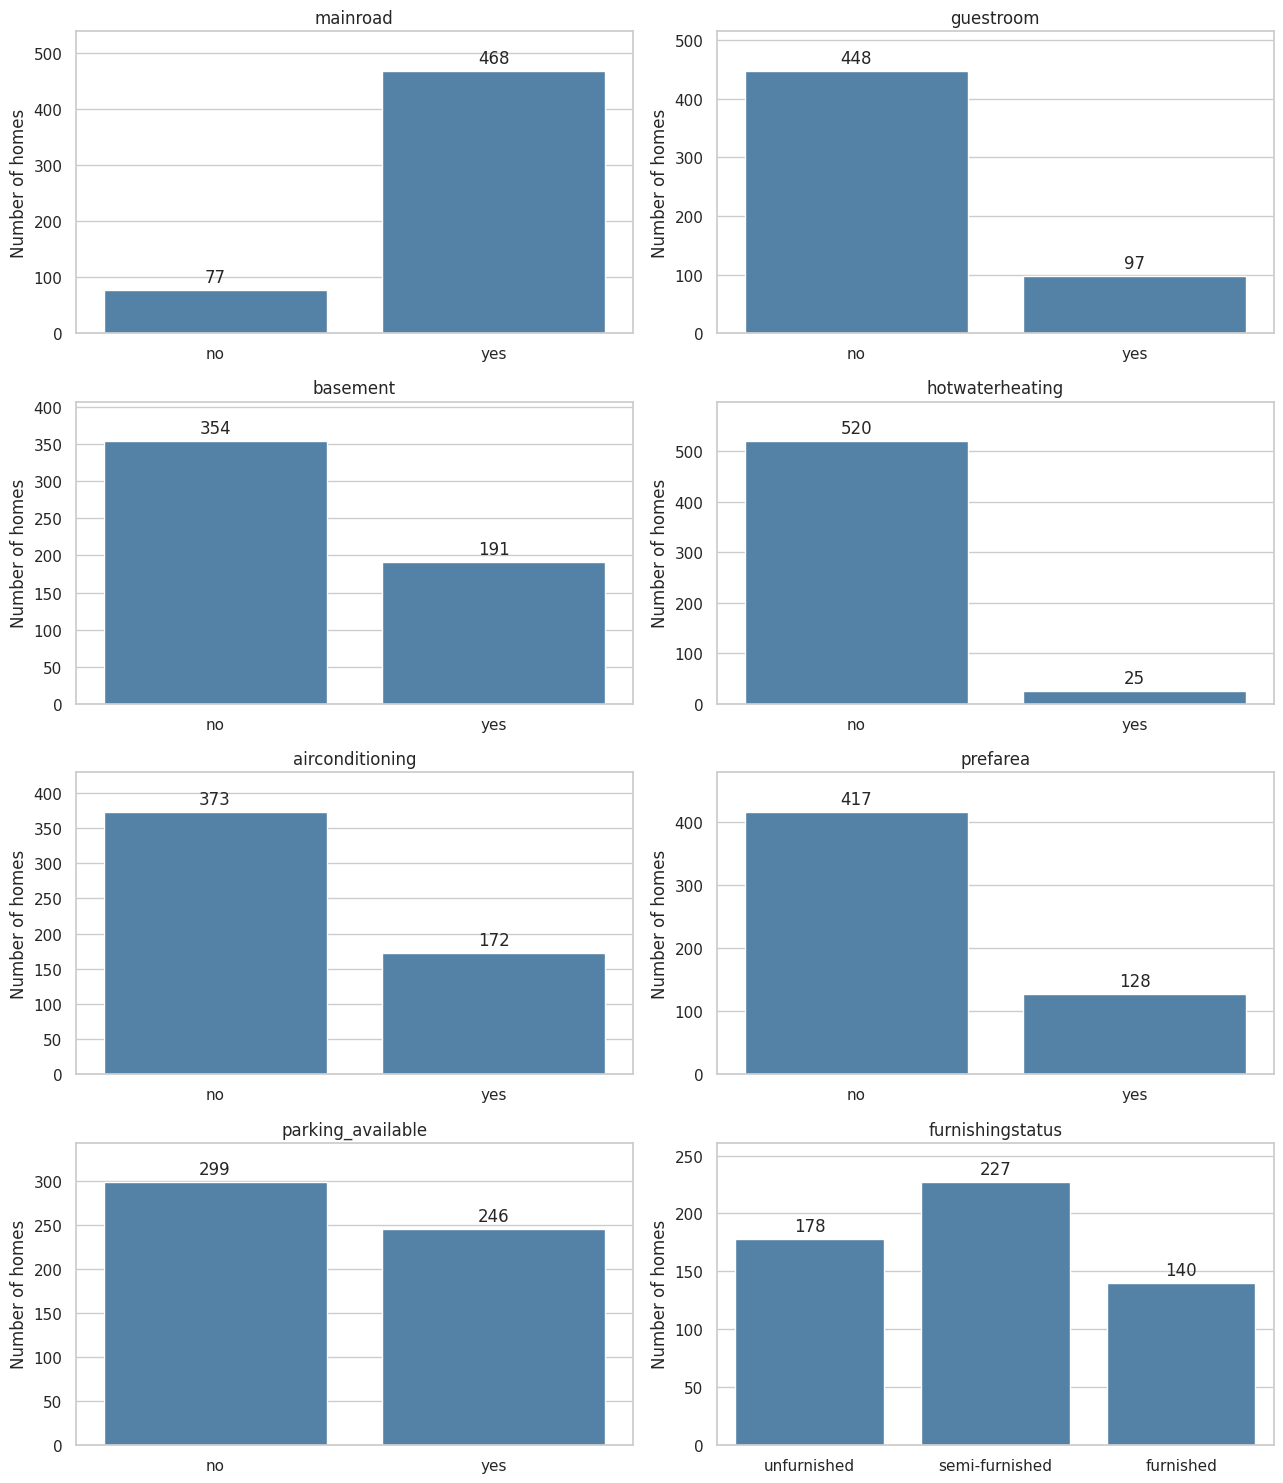

In [ ]:
# Cell 11: Create readable parking labels for EDA.
df_eda = df.copy()

df_eda["parking_available"] = np.where(
    df_eda["parking"] >= 1, "yes", "no"
)

categorical_predictors = yes_no_columns + [
    "parking_available", "furnishingstatus"
]

category_orders = {
    column: ["no", "yes"]
    for column in yes_no_columns + ["parking_available"]
}

category_orders["furnishingstatus"] = [
    "unfurnished", "semi-furnished", "furnished"
]

fig, axes = plt.subplots(4, 2, figsize=(13, 15))

for ax, column in zip(axes.flat, categorical_predictors):
    sns.countplot(
        data=df_eda,
        x=column,
        order=category_orders[column],
        color="steelblue",
        ax=ax
    )

    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("Number of homes")
    ax.bar_label(ax.containers[0], padding=3)
    ax.margins(y=0.15)

plt.tight_layout()
plt.show()

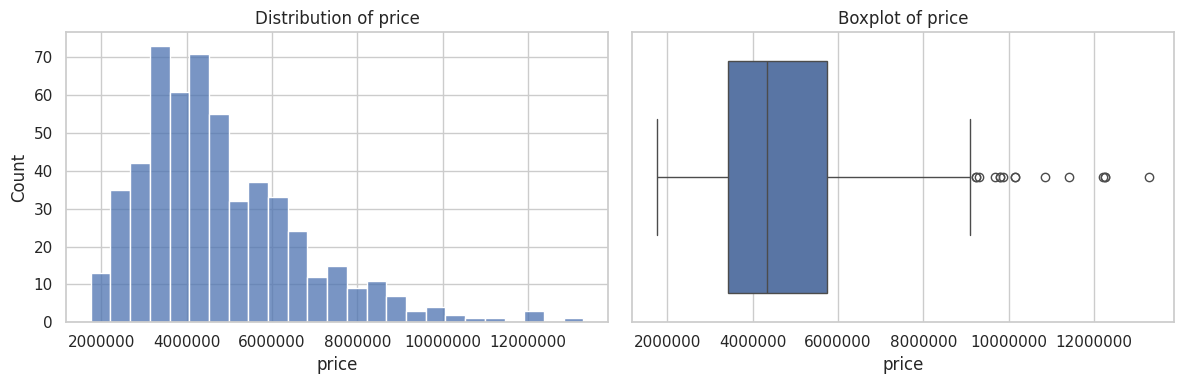

,Original-scale skewness
price,1.212239
area,1.321188


In [ ]:
# Cell 12: Plot price before transformation.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="price", bins=25, ax=axes[0])
sns.boxplot(data=df, x="price", ax=axes[1])

axes[0].set_title("Distribution of price")
axes[1].set_title("Boxplot of price")

# Display ordinary numbers instead of scientific notation.
for ax in axes:
    ax.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

# Skewness describes asymmetry.
display(
    df[["price", "area"]]
    .skew()
    .rename("Original-scale skewness")
    .to_frame()
)

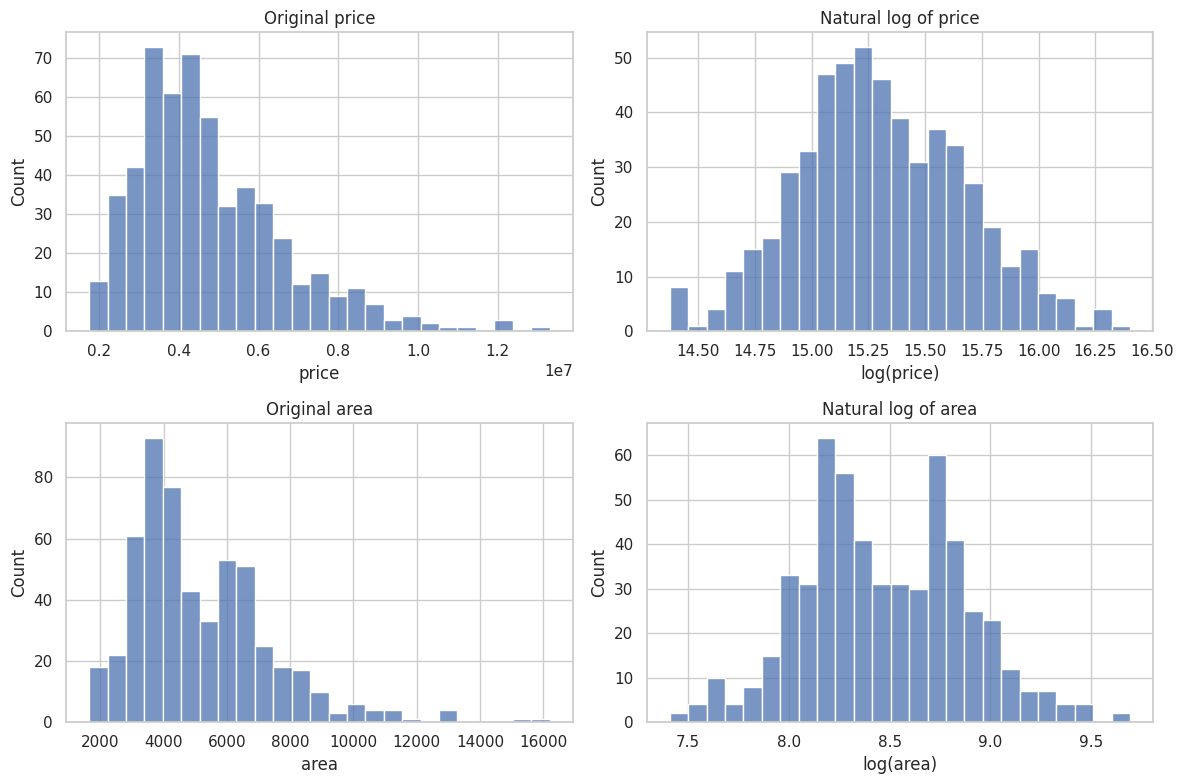

,original_skewness,log_skewness
variable,,
price,1.212,0.141
area,1.321,0.134


In [ ]:
# Cell 13: Preview natural logs without replacing original columns.
if (df[["price", "area"]] <= 0).any().any():
    raise ValueError("Natural logs require strictly positive values.")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
skewness_rows = []

for row, column in enumerate(["price", "area"]):
    original = df[column]
    logged = np.log(original)

    sns.histplot(x=original, bins=25, ax=axes[row, 0])
    sns.histplot(x=logged, bins=25, ax=axes[row, 1])

    axes[row, 0].set_title(f"Original {column}")
    axes[row, 1].set_title(f"Natural log of {column}")
    axes[row, 1].set_xlabel(f"log({column})")

    skewness_rows.append({
        "variable": column,
        "original_skewness": original.skew(),
        "log_skewness": logged.skew()
    })

plt.tight_layout()
plt.show()

display(pd.DataFrame(skewness_rows).set_index("variable").round(3))

In [ ]:
# Cell 14: Add log columns while preserving original measurements.
df_analysis["log_price"] = np.log(df_analysis["price"])
df_analysis["log_area"] = np.log(df_analysis["area"])

df_eda["log_price"] = np.log(df_eda["price"])
df_eda["log_area"] = np.log(df_eda["area"])

response_column = "log_price"

display(
    df_analysis[["price", "log_price", "area", "log_area"]].head()
)

,price,log_price,area,log_area
0,13300000,16.403275,7420,8.911934
1,12250000,16.321036,8960,9.100526
2,12250000,16.321036,9960,9.206332
3,12215000,16.318175,7500,8.922658
4,11410000,16.250001,7420,8.911934


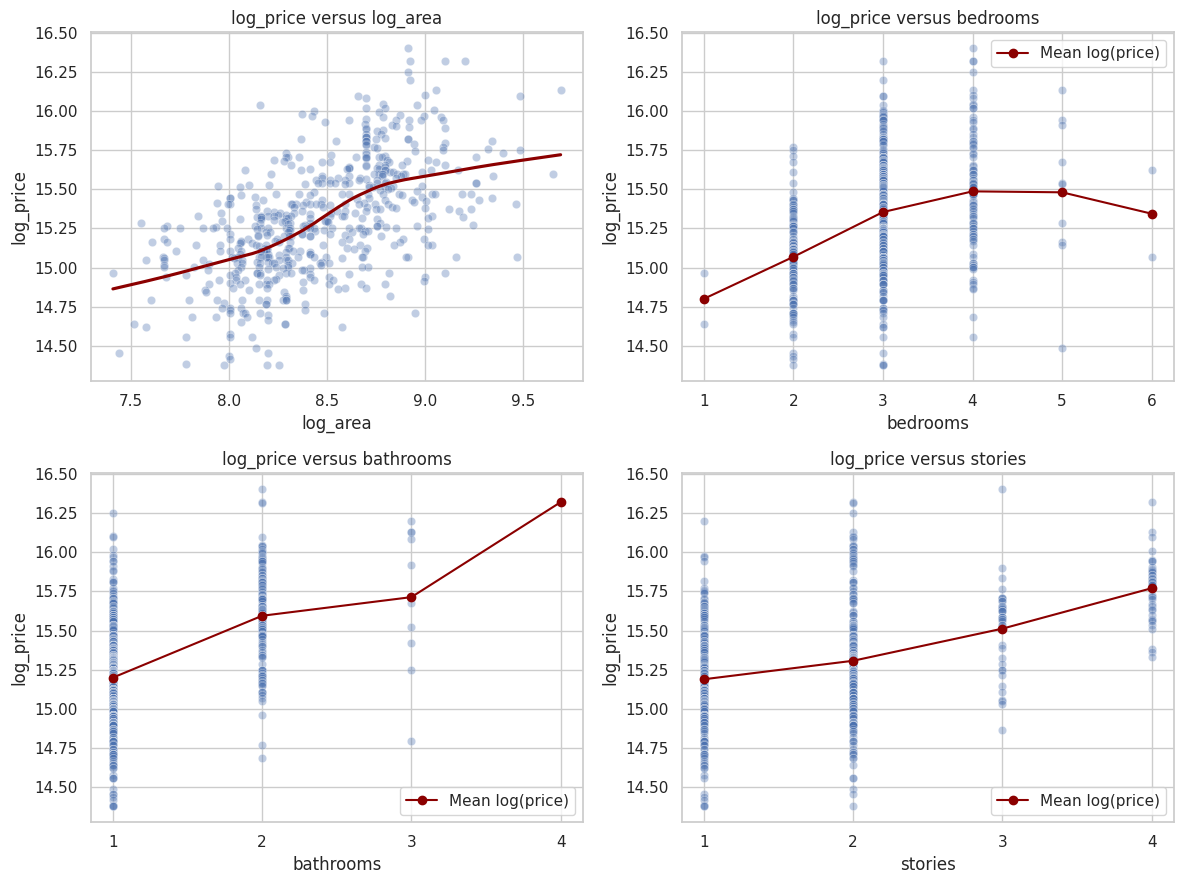

In [ ]:
# Cell 15: Examine each numeric predictor against log(price).
plot_predictors = ["log_area", "bedrooms", "bathrooms", "stories"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, column in zip(axes.flat, plot_predictors):
    sns.scatterplot(
        data=df_eda,
        x=column,
        y=response_column,
        alpha=0.35,
        ax=ax
    )

    if column == "log_area":
        # A smooth curve helps reveal curvature.
        sns.regplot(
            data=df_eda,
            x=column,
            y=response_column,
            scatter=False,
            lowess=True,
            color="darkred",
            ax=ax
        )
    else:
        # For discrete counts, show the mean at each observed count.
        group_means = df_eda.groupby(column)[response_column].mean()
        ax.plot(
            group_means.index,
            group_means.values,
            "o-",
            color="darkred",
            label="Mean log(price)"
        )
        ax.legend()

        # Show only observed whole-number counts.
        counts = sorted(df_eda[column].dropna().unique())
        ax.set_xticks(counts)
        ax.set_xticklabels([str(int(value)) for value in counts])

    ax.set_title(f"{response_column} versus {column}")

plt.tight_layout()
plt.show()

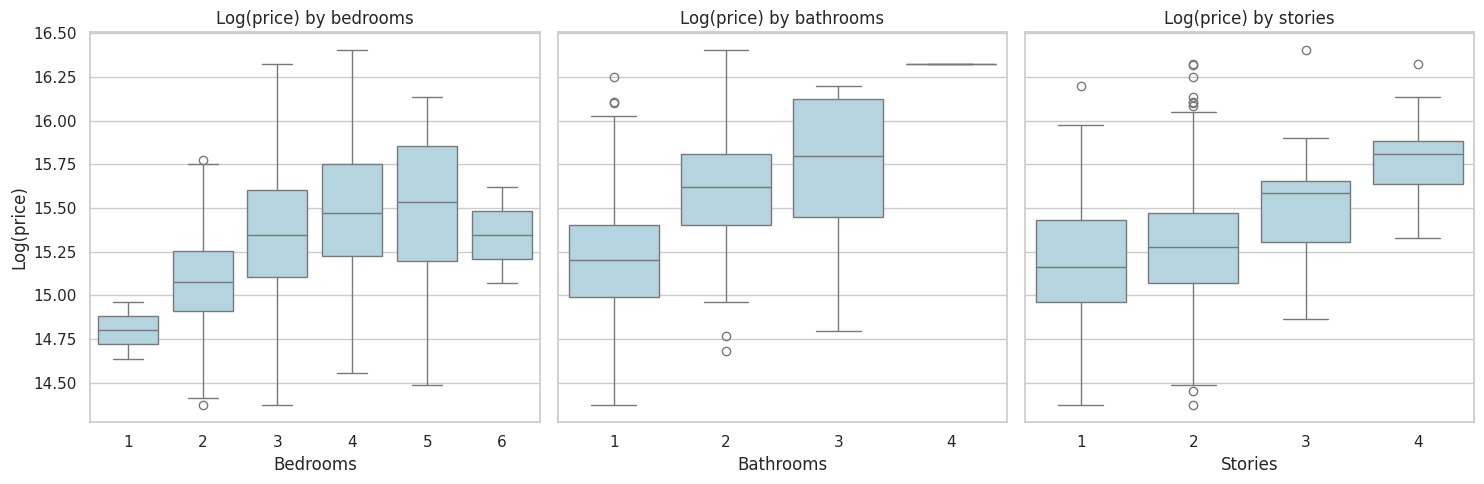

In [ ]:
# Cell 15a: Boxplots of log(price) by discrete numeric predictors.
boxplot_predictors = ["bedrooms", "bathrooms", "stories"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, column in zip(axes, boxplot_predictors):
    counts = sorted(df_eda[column].dropna().unique())

    sns.boxplot(
        data=df_eda,
        x=column,
        y=response_column,
        order=counts,
        color="lightblue",
        ax=ax
    )

    # Display whole-number labels at categorical positions.
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels([str(int(value)) for value in counts])

    ax.set_title(f"Log(price) by {column}")
    ax.set_xlabel(column.capitalize())
    ax.set_ylabel("")

axes[0].set_ylabel("Log(price)")

plt.tight_layout()
plt.show()

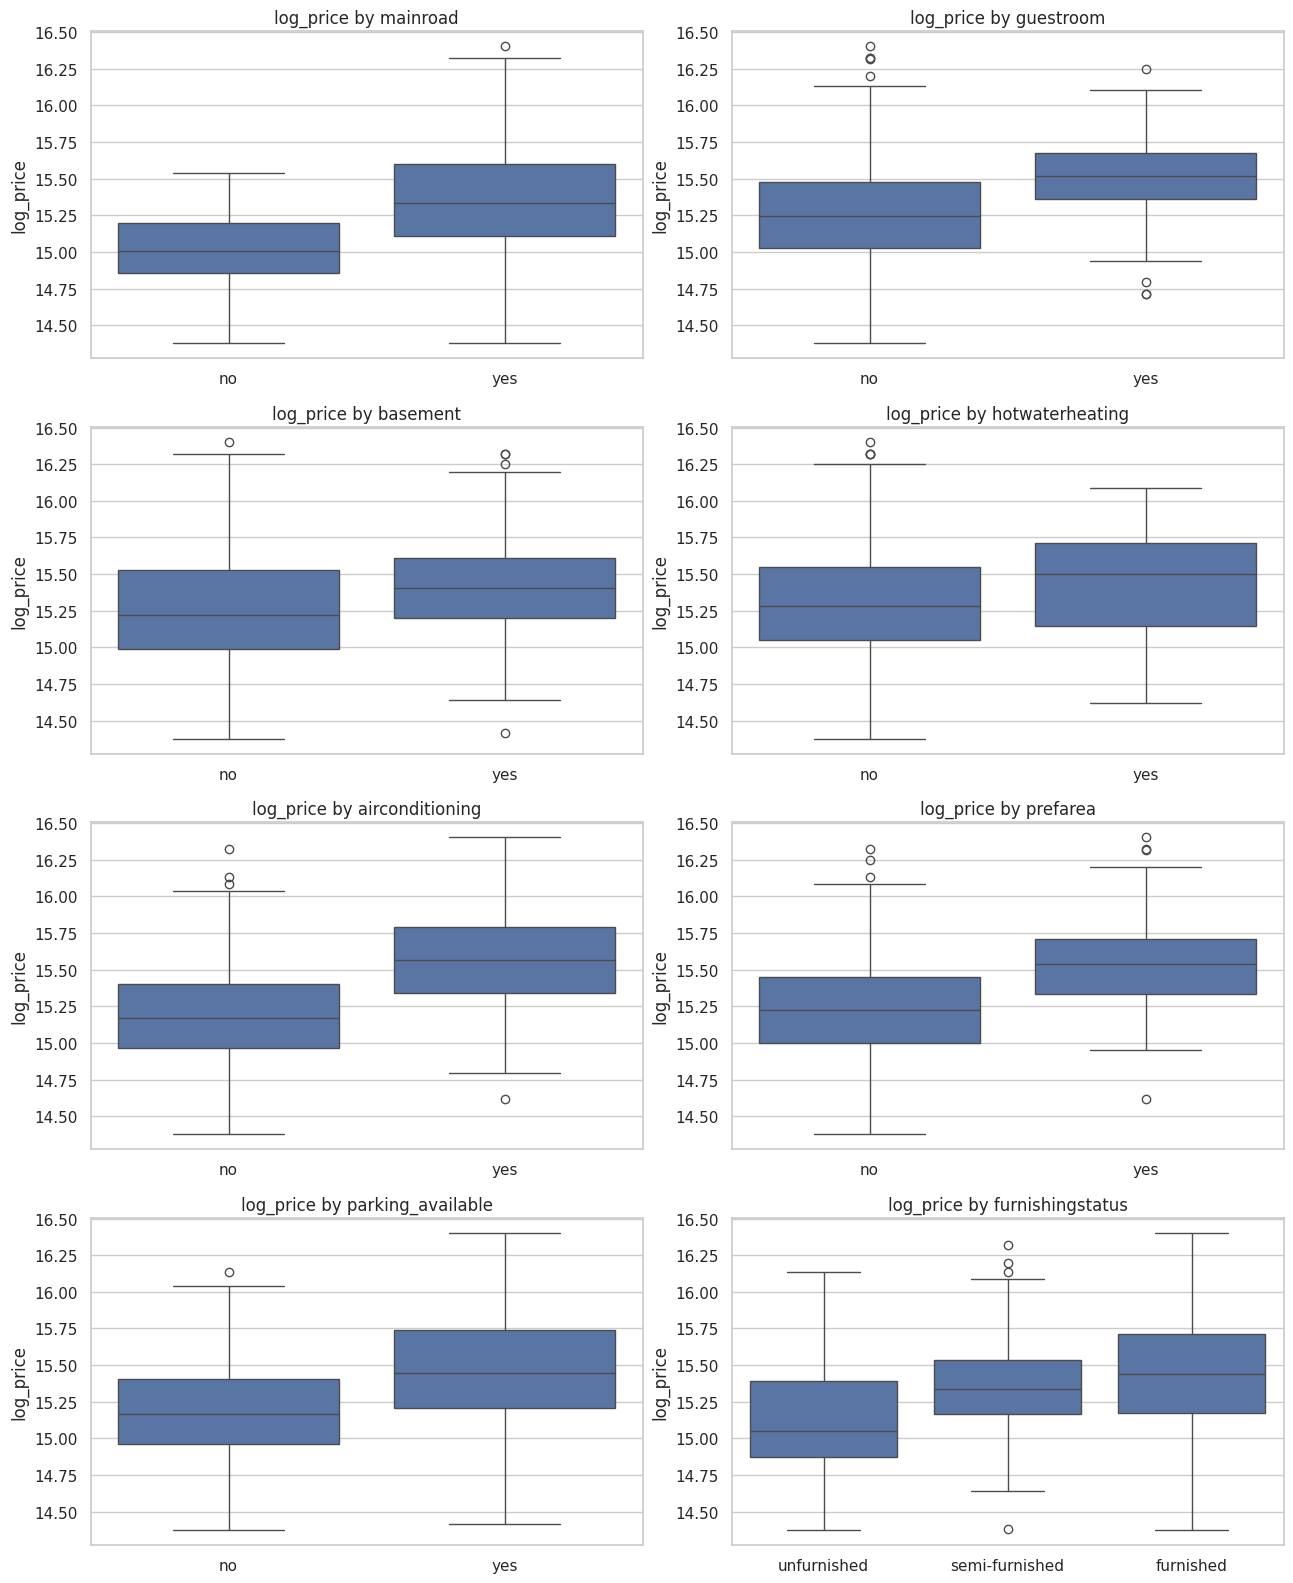

In [ ]:
# Cell 16: Compare response distributions across categories.
fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for ax, column in zip(axes.flat, categorical_predictors):
    sns.boxplot(
        data=df_eda,
        x=column,
        y=response_column,
        order=category_orders[column],
        ax=ax
    )

    ax.set_title(f"{response_column} by {column}")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

,count,min,median,max
prefarea,,,,
no,417,1650,4300.0,16200
yes,128,1950,6360.0,13200


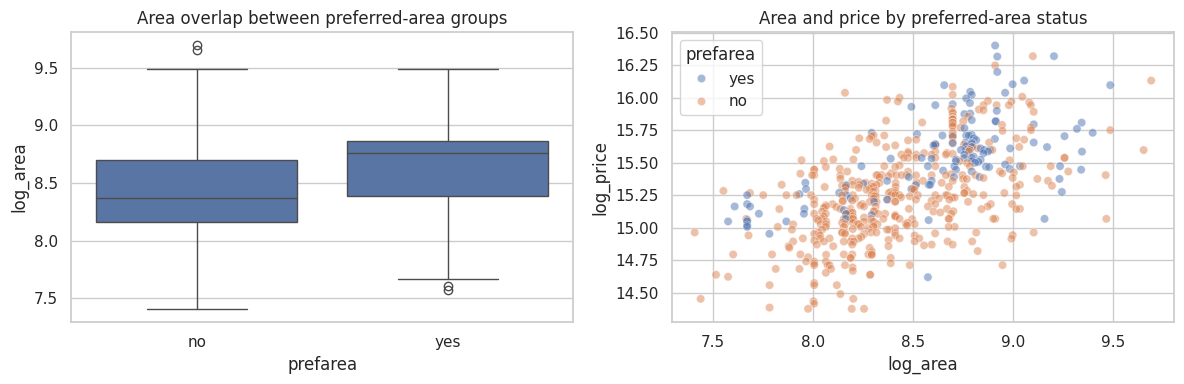

In [ ]:
# Cell 17: Examine area distributions within preferred-area groups.
display(
    df_eda.groupby("prefarea")["area"]
    .agg(["count", "min", "median", "max"])
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(
    data=df_eda,
    x="prefarea",
    y="log_area",
    order=["no", "yes"],
    ax=axes[0]
)

sns.scatterplot(
    data=df_eda,
    x="log_area",
    y="log_price",
    hue="prefarea",
    alpha=0.5,
    ax=axes[1]
)

axes[0].set_title("Area overlap between preferred-area groups")
axes[1].set_title("Area and price by preferred-area status")

plt.tight_layout()
plt.show()

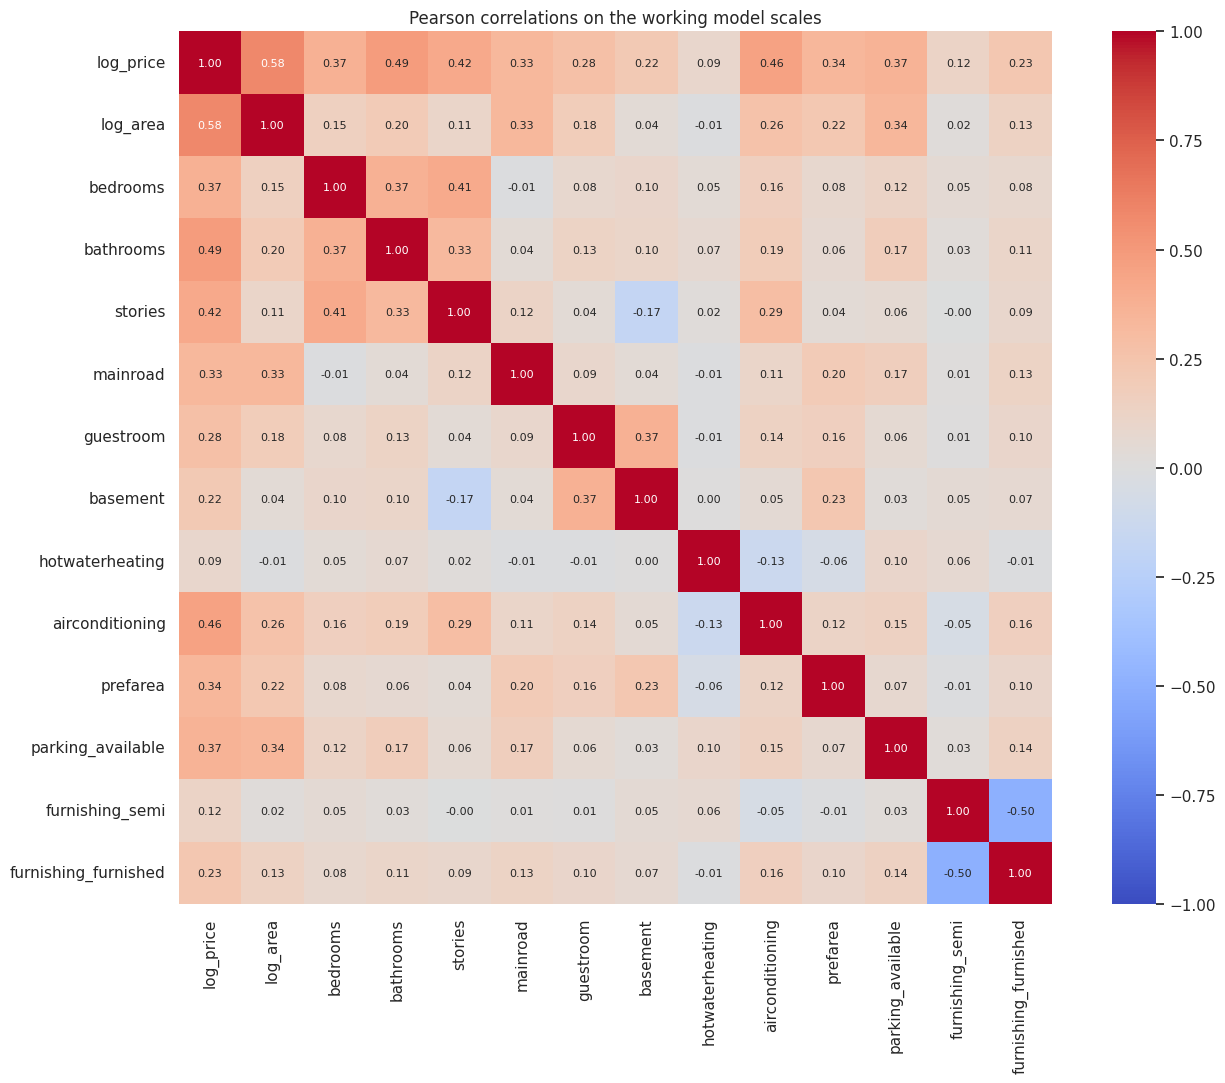

In [ ]:
# Cell 18: Correlations on the working model scales.
# Include only one representation of each predictor.
main_effect_predictors = (
    ["log_area", "bedrooms", "bathrooms", "stories"]
    + binary_predictors
    + furnishing_dummies
)

correlation_columns = [response_column] + main_effect_predictors

correlation_matrix = df_analysis[correlation_columns].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    annot_kws={"size": 8}
)

plt.title("Pearson correlations on the working model scales")
plt.tight_layout()
plt.show()

In [ ]:
# Cell 19: A reusable function for variance inflation factors.
def calculate_vif(data, columns):
    X = data[columns].astype(float)

    if not np.isfinite(X.to_numpy()).all():
        raise ValueError("VIF inputs must be finite and nonmissing.")

    # Include an intercept in the auxiliary regressions.
    X = sm.add_constant(X, has_constant="add")

    if np.linalg.matrix_rank(X.to_numpy()) < X.shape[1]:
        raise ValueError("The design matrix has exact linear dependence.")

    rows = []

    for i, column in enumerate(X.columns):
        if column != "const":
            rows.append({
                "predictor": column,
                "VIF": variance_inflation_factor(X.to_numpy(), i)
            })

    result = pd.DataFrame(rows)

    result["screening_note"] = np.select(
        [result["VIF"] > 10, result["VIF"] > 5],
        ["Serious flag", "Warning"],
        default="Below warning threshold"
    )

    return result.sort_values("VIF", ascending=False).reset_index(drop=True)


vif_main_effects = calculate_vif(df_analysis, main_effect_predictors)
display(vif_main_effects.round(2))

,predictor,VIF,screening_note
0,stories,1.47,Below warning threshold
1,furnishing_furnished,1.45,Below warning threshold
2,log_area,1.38,Below warning threshold
3,furnishing_semi,1.38,Below warning threshold
4,bedrooms,1.36,Below warning threshold
5,basement,1.33,Below warning threshold
6,bathrooms,1.29,Below warning threshold
7,airconditioning,1.22,Below warning threshold
8,guestroom,1.22,Below warning threshold
9,mainroad,1.19,Below warning threshold


# Build 3 MLR models

In [ ]:
# Cell 20: Prepare one dataset for all three models.
baseline_predictors = [
    "log_area",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking_available"
]

additional_predictors = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea",
    "furnishing_semi",
    "furnishing_furnished"
]

required_columns = (
    ["log_price"] + baseline_predictors + additional_predictors
)

model_data = df_analysis[required_columns].copy().astype(float)

# Stop rather than silently analyze different samples.
if not np.isfinite(model_data.to_numpy()).all():
    raise ValueError("Resolve missing or non-finite values before modeling.")

# Center log(area) using the same value for all models.
log_area_center = model_data["log_area"].mean()

model_data["log_area_c"] = (
    model_data["log_area"] - log_area_center
)

# The original-scale area corresponding to centered log(area) = 0.
reference_area = np.exp(log_area_center)

print("Number of homes:", len(model_data))
print("Mean centered log(area):",
      round(model_data["log_area_c"].mean(), 10))
print("Reference area (original recorded units):",
      round(reference_area, 2))

Number of homes: 545
Mean centered log(area): -0.0
Reference area (original recorded units): 4753.03


In [ ]:
# Cell 21: Fit the baseline model.
formula_m1 = (
    "log_price ~ log_area_c + bedrooms + bathrooms "
    "+ stories + parking_available"
)

model1 = smf.ols(
    formula=formula_m1,
    data=model_data,
    missing="raise"
).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.567
Model:                            OLS   Adj. R-squared:                  0.563
Method:                 Least Squares   F-statistic:                     140.9
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           2.03e-95
Time:                        00:07:22   Log-Likelihood:                -6.3188
No. Observations:                 545   AIC:                             24.64
Df Residuals:                     539   BIC:                             50.44
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            14.6877      0.04

In [ ]:
# Cell 22: Add amenities, preferred-area status, and furnishing.
formula_m2 = (
    formula_m1
    + " + "
    + " + ".join(additional_predictors)
)

model2 = smf.ols(
    formula=formula_m2,
    data=model_data,
    missing="raise"
).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.704
Method:                 Least Squares   F-statistic:                     100.3
Date:                Fri, 23 Oct 2026   Prob (F-statistic):          1.27e-133
Time:                        00:07:22   Log-Likelihood:                 103.79
No. Observations:                 545   AIC:                            -179.6
Df Residuals:                     531   BIC:                            -119.4
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               14.5120 

In [ ]:
# Cell 23: Add the prespecified interaction.
# ":" adds only the interaction because both main effects are already present.
formula_m3 = formula_m2 + " + log_area_c:prefarea"

model3 = smf.ols(
    formula=formula_m3,
    data=model_data,
    missing="raise"
).fit()

print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.703
Method:                 Least Squares   F-statistic:                     92.99
Date:                Fri, 23 Oct 2026   Prob (F-statistic):          1.25e-132
Time:                        00:07:22   Log-Likelihood:                 103.83
No. Observations:                 545   AIC:                            -177.7
Df Residuals:                     530   BIC:                            -113.1
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               14.5103 

In [ ]:
# Cell 24: Estimate area elasticities within each group.
# These currently use conventional OLS standard errors.
slope_tests = {
    "Non-preferred area": model3.t_test("log_area_c = 0"),
    "Preferred area": model3.t_test(
        "log_area_c + log_area_c:prefarea = 0"
    ),
    "Difference: preferred minus non-preferred": model3.t_test(
        "log_area_c:prefarea = 0"
    )
}

slope_rows = []

for label, test in slope_tests.items():
    lower, upper = np.asarray(test.conf_int()).reshape(-1)

    slope_rows.append({
        "comparison": label,
        "estimate": np.asarray(test.effect).item(),
        "standard_error": np.asarray(test.sd).item(),
        "CI_lower": lower,
        "CI_upper": upper,
        "p_value": np.asarray(test.pvalue).item()
    })

area_slopes = pd.DataFrame(slope_rows).set_index("comparison")
display(area_slopes.round(4))

,estimate,standard_error,CI_lower,CI_upper,p_value
comparison,,,,,
Non-preferred area,0.2907,0.0303,0.2313,0.3502,0.0000
Preferred area,0.3042,0.0427,0.2203,0.3881,0.0000
Difference: preferred minus non-preferred,0.0134,0.0501,-0.0851,0.1119,0.7887


In [ ]:
# Cell 25: Store models for later diagnostics and comparisons.
models = {
    "Model 1": model1,
    "Model 2": model2,
    "Model 3": model3
}

reference_rows = model1.model.data.row_labels

for name, model in models.items():
    assert list(model.model.data.row_labels) == list(reference_rows)
    assert int(model.nobs) == len(model_data)

model_structure = pd.DataFrame({
    name: {
        "Observations": int(model.nobs),
        "Slope parameters": int(model.df_model),
        "Parameters including intercept": len(model.params)
    }
    for name, model in models.items()
}).T

display(model_structure)

,Observations,Slope parameters,Parameters including intercept
Model 1,545,5,6
Model 2,545,13,14
Model 3,545,14,15


In [ ]:
# Cell 26: Extract coefficient results without the extra summary statistics.
def coefficient_table(model):
    confidence_intervals = model.conf_int(alpha=0.05)

    return pd.DataFrame({
        "coefficient": model.params,
        "standard_error": model.bse,
        "t_statistic": model.tvalues,
        "p_value": model.pvalues,
        "CI_lower": confidence_intervals.iloc[:, 0],
        "CI_upper": confidence_intervals.iloc[:, 1]
    })

for name, model in models.items():
    print(f"\n{name}: conventional OLS inference")
    display(coefficient_table(model).round(4))


Model 1: conventional OLS inference


,coefficient,standard_error,t_statistic,p_value,CI_lower,CI_upper
Intercept,14.6877,0.0466,315.3393,0.0000,14.5962,14.7792
log_area_c,0.4090,0.0286,14.2938,0.0000,0.3528,0.4652
bedrooms,0.0469,0.0164,2.8667,0.0043,0.0148,0.0791
bathrooms,0.1923,0.0235,8.1741,0.0000,0.1461,0.2385
stories,0.1015,0.0136,7.4500,0.0000,0.0747,0.1283
parking_available,0.1099,0.0227,4.8410,0.0000,0.0653,0.1545



Model 2: conventional OLS inference


,coefficient,standard_error,t_statistic,p_value,CI_lower,CI_upper
Intercept,14.5120,0.0460,315.1797,0.0000,14.4215,14.6024
log_area_c,0.2950,0.0257,11.4948,0.0000,0.2446,0.3455
bedrooms,0.0312,0.0137,2.2713,0.0235,0.0042,0.0582
bathrooms,0.1605,0.0196,8.1836,0.0000,0.1220,0.1990
stories,0.0886,0.0121,7.2936,0.0000,0.0647,0.1125
parking_available,0.0797,0.0190,4.1951,0.0000,0.0424,0.1171
mainroad,0.1005,0.0272,3.6948,0.0002,0.0471,0.1540
guestroom,0.0507,0.0251,2.0198,0.0439,0.0014,0.0999
basement,0.0963,0.0210,4.5965,0.0000,0.0552,0.1375
hotwaterheating,0.1569,0.0425,3.6950,0.0002,0.0735,0.2404



Model 3: conventional OLS inference


,coefficient,standard_error,t_statistic,p_value,CI_lower,CI_upper
Intercept,14.5103,0.0465,312.0592,0.0000,14.4190,14.6017
log_area_c,0.2907,0.0303,9.6030,0.0000,0.2313,0.3502
bedrooms,0.0313,0.0138,2.2737,0.0234,0.0043,0.0583
bathrooms,0.1605,0.0196,8.1781,0.0000,0.1220,0.1991
stories,0.0888,0.0122,7.2911,0.0000,0.0648,0.1127
parking_available,0.0794,0.0191,4.1630,0.0000,0.0419,0.1168
mainroad,0.1019,0.0277,3.6794,0.0003,0.0475,0.1563
guestroom,0.0509,0.0251,2.0253,0.0433,0.0015,0.1002
basement,0.0959,0.0210,4.5655,0.0000,0.0547,0.1372
hotwaterheating,0.1572,0.0425,3.6976,0.0002,0.0737,0.2408


In [ ]:
# Compare the models using their unrounded stored results.
comparison_table = pd.DataFrame({
    name: {
        "N": int(model.nobs),
        "Parameters incl. intercept": len(model.params),
        "R_squared": model.rsquared,
        "Adjusted_R_squared": model.rsquared_adj,
        "AIC": model.aic,
        "BIC_SBC": model.bic
    }
    for name, model in models.items()
}).T

# Differences from the lowest score: zero identifies the preferred model.
comparison_table["Delta_AIC"] = (
    comparison_table["AIC"] - comparison_table["AIC"].min()
)

comparison_table["Delta_BIC"] = (
    comparison_table["BIC_SBC"] - comparison_table["BIC_SBC"].min()
)

display(comparison_table.round(3))

,N,Parameters incl. intercept,R_squared,Adjusted_R_squared,AIC,BIC_SBC,Delta_AIC,Delta_BIC
Model 1,545.0,6.0,0.567,0.563,24.638,50.442,204.214,169.807
Model 2,545.0,14.0,0.711,0.704,-179.576,-119.365,0.000,0.000
Model 3,545.0,15.0,0.711,0.703,-177.650,-113.138,1.926,6.227


# Validate assumptions

Linearity: residuals versus fitted values

In [ ]:
# Cell 27: Set the provisional main model and import diagnostic tools.
main_model = model2
main_model_name = "Model 2"

# Retain the exact rows and order used to fit the model.
main_rows = main_model.model.data.row_labels
diagnostic_data = model_data.loc[main_rows].copy()

diagnostic_data["fitted"] = main_model.fittedvalues
diagnostic_data["residual"] = main_model.resid

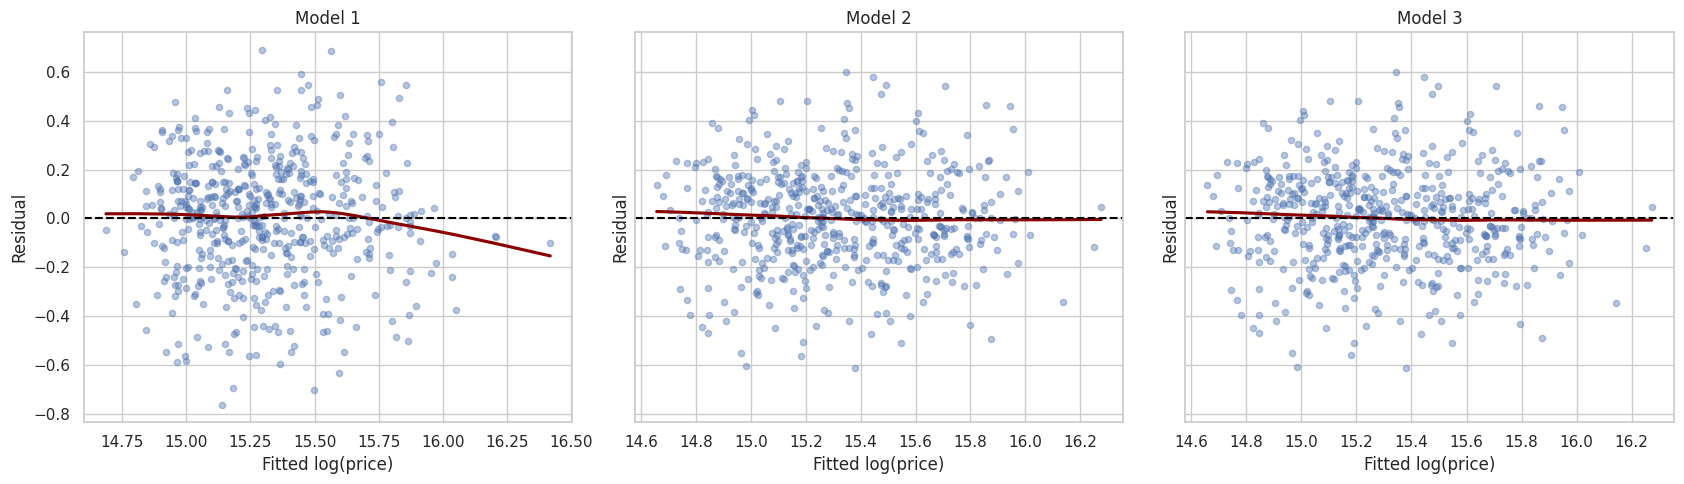

In [ ]:
# Cell 28: Compare residual-versus-fitted plots for all three models.
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)

for ax, (name, model) in zip(axes, models.items()):
    sns.regplot(
        x=model.fittedvalues,
        y=model.resid,
        lowess=True,
        scatter_kws={"alpha": 0.4, "s": 20},
        line_kws={"color": "darkred"},
        ax=ax
    )

    ax.axhline(0, color="black", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Fitted log(price)")
    ax.set_ylabel("Residual")

plt.tight_layout()
plt.show()

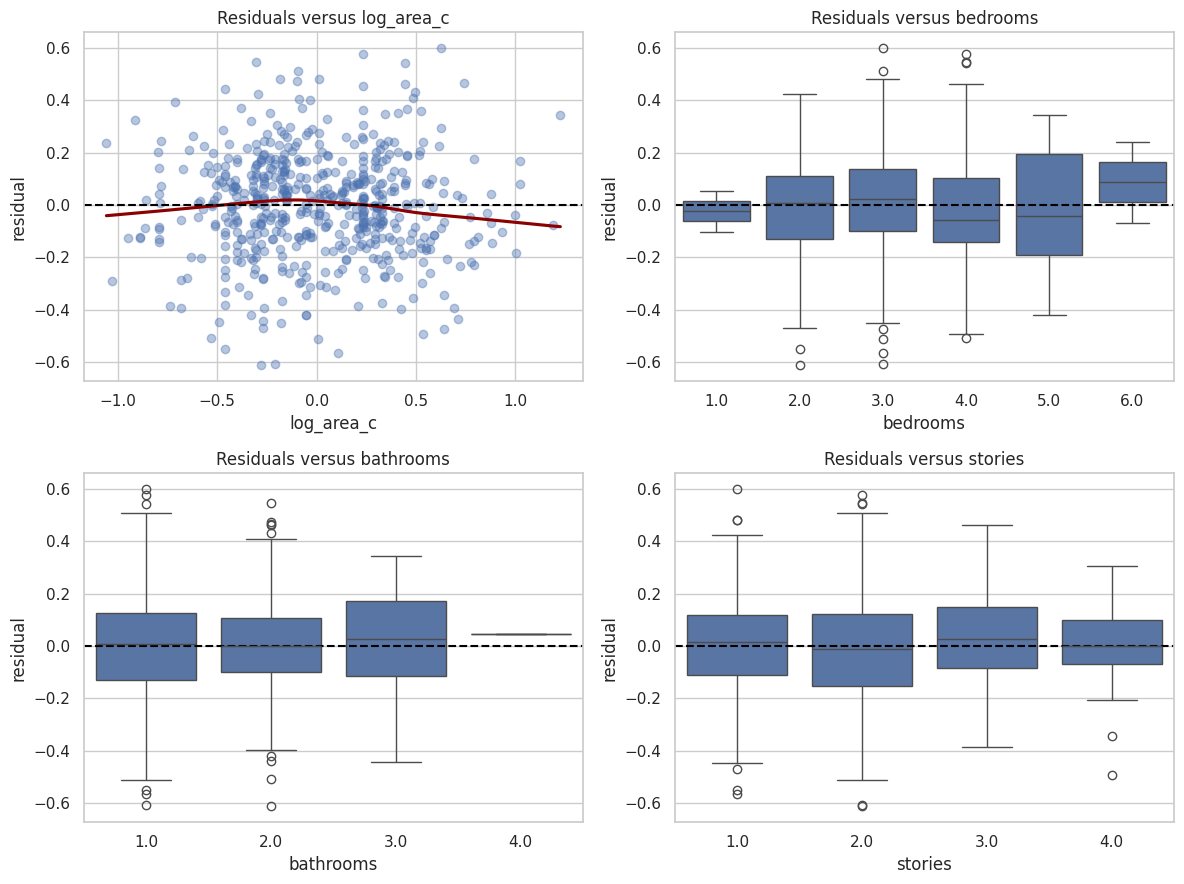


bedrooms:


,count,mean,median
bedrooms,,,
1.0,2,-0.024452,-0.024452
2.0,136,-0.014410,0.006925
3.0,300,0.014451,0.021673
4.0,95,-0.025498,-0.056200
5.0,10,-0.007828,-0.043894
6.0,2,0.086886,0.086886



bathrooms:


,count,mean,median
bathrooms,,,
1.0,401,0.000299,0.007477
2.0,133,-0.001462,-0.000651
3.0,10,0.002939,0.026020
4.0,1,0.045235,0.045235



stories:


,count,mean,median
stories,,,
1.0,227,0.007557,0.015165
2.0,238,-0.012974,-0.012416
3.0,39,0.026404,0.027301
4.0,41,0.008361,0.001905


In [ ]:
# Cell 29: Inspect Model 2 residuals against numeric predictors.
check_predictors = ["log_area_c", "bedrooms", "bathrooms", "stories"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, column in zip(axes.flat, check_predictors):
    if column == "log_area_c":
        sns.regplot(
            data=diagnostic_data,
            x=column,
            y="residual",
            lowess=True,
            scatter_kws={"alpha": 0.4},
            line_kws={"color": "darkred"},
            ax=ax
        )
    else:
        sns.boxplot(
            data=diagnostic_data,
            x=column,
            y="residual",
            ax=ax
        )

    ax.axhline(0, color="black", linestyle="--")
    ax.set_title(f"Residuals versus {column}")

plt.tight_layout()
plt.show()

# Group sizes help interpret sparse count categories.
for column in ["bedrooms", "bathrooms", "stories"]:
    print(f"\n{column}:")
    display(
        diagnostic_data.groupby(column)["residual"]
        .agg(["count", "mean", "median"])
    )

Homoscedasticity: residual plots and Breusch–Pagan

In [ ]:
# Cell 30: Breusch-Pagan diagnostics for all three models.
bp_rows = []

for name, model in models.items():
    # robust=True uses the Koenker version of the BP test.
    # This is distinct from HC3 robust standard errors.
    lm_stat, lm_p, f_stat, f_p = het_breuschpagan(
        model.resid,
        model.model.exog,
        robust=True
    )

    bp_rows.append({
        "model": name,
        "LM_statistic": lm_stat,
        "LM_p_value": lm_p,
        "F_statistic": f_stat,
        "F_p_value": f_p
    })

bp_results = pd.DataFrame(bp_rows).set_index("model")
display(bp_results.round(6))

,LM_statistic,LM_p_value,F_statistic,F_p_value
model,,,,
Model 1,12.916689,0.024172,2.616919,0.023717
Model 2,31.472999,0.002874,2.503376,0.002477
Model 3,32.725463,0.003155,2.418415,0.002706


In [ ]:
# Cell 31: Calculate HC3 robust standard errors for each model.
robust_models = {
    name: model.get_robustcov_results(cov_type="HC3", use_t=True)
    for name, model in models.items()
}

main_robust = robust_models[main_model_name]

print(main_robust.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.704
Method:                 Least Squares   F-statistic:                     102.1
Date:                Fri, 23 Oct 2026   Prob (F-statistic):          5.04e-135
Time:                        00:07:24   Log-Likelihood:                 103.79
No. Observations:                 545   AIC:                            -179.6
Df Residuals:                     531   BIC:                            -119.4
Df Model:                          13                                         
Covariance Type:                  HC3                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               14.5120 

In [ ]:
# Cell 32: Compare conventional and HC3 inference for Model 2.
ols_ci = np.asarray(main_model.conf_int())
hc3_ci = np.asarray(main_robust.conf_int())

inference_comparison = pd.DataFrame(
    {
        "coefficient": np.asarray(main_model.params),
        "OLS_SE": np.asarray(main_model.bse),
        "HC3_SE": np.asarray(main_robust.bse),
        "OLS_p": np.asarray(main_model.pvalues),
        "HC3_p": np.asarray(main_robust.pvalues),
        "OLS_CI_lower": ols_ci[:, 0],
        "OLS_CI_upper": ols_ci[:, 1],
        "HC3_CI_lower": hc3_ci[:, 0],
        "HC3_CI_upper": hc3_ci[:, 1]
    },
    index=main_model.model.exog_names
)

display(inference_comparison.round(4))

,coefficient,OLS_SE,HC3_SE,OLS_p,HC3_p,OLS_CI_lower,OLS_CI_upper,HC3_CI_lower,HC3_CI_upper
Intercept,14.5120,0.0460,0.0467,0.0000,0.0000,14.4215,14.6024,14.4203,14.6037
log_area_c,0.2950,0.0257,0.0261,0.0000,0.0000,0.2446,0.3455,0.2438,0.3463
bedrooms,0.0312,0.0137,0.0143,0.0235,0.0297,0.0042,0.0582,0.0031,0.0593
bathrooms,0.1605,0.0196,0.0216,0.0000,0.0000,0.1220,0.1990,0.1181,0.2029
stories,0.0886,0.0121,0.0115,0.0000,0.0000,0.0647,0.1125,0.0660,0.1112
parking_available,0.0797,0.0190,0.0186,0.0000,0.0000,0.0424,0.1171,0.0431,0.1163
mainroad,0.1005,0.0272,0.0280,0.0002,0.0004,0.0471,0.1540,0.0456,0.1555
guestroom,0.0507,0.0251,0.0261,0.0439,0.0527,0.0014,0.0999,-0.0006,0.1019
basement,0.0963,0.0210,0.0235,0.0000,0.0000,0.0552,0.1375,0.0501,0.1426
hotwaterheating,0.1569,0.0425,0.0543,0.0002,0.0040,0.0735,0.2404,0.0502,0.2637


Normality of residuals

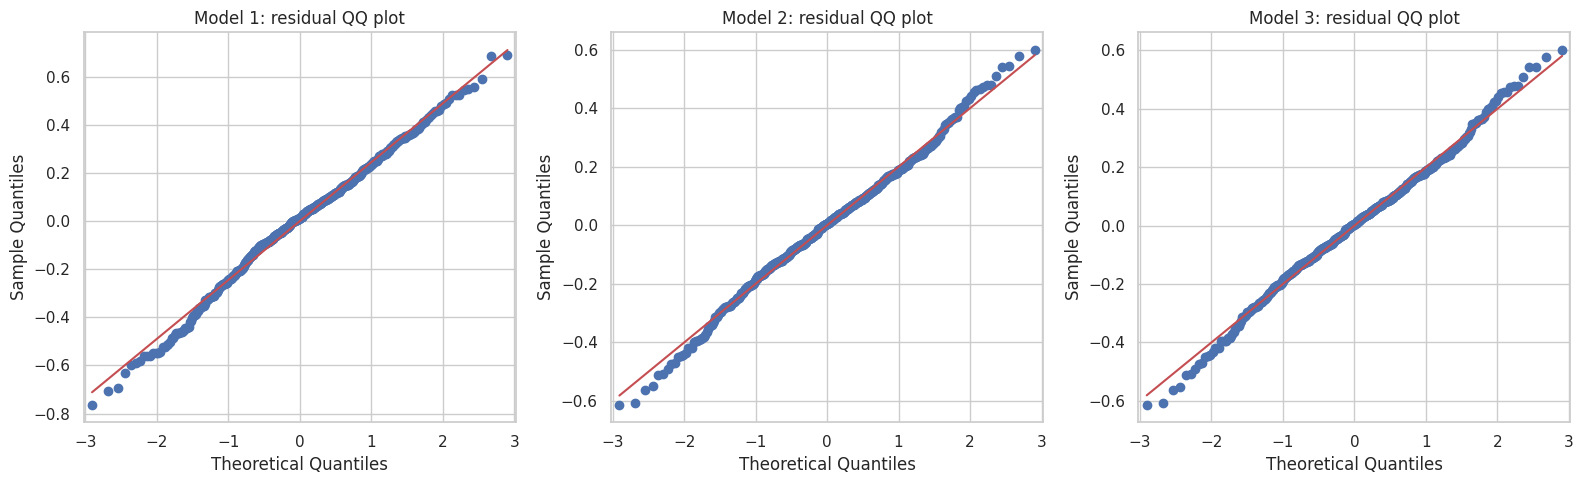

In [ ]:
# Cell 33: QQ plots for all models.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, models.items()):
    sm.qqplot(model.resid, line="s", ax=ax)
    ax.set_title(f"{name}: residual QQ plot")

plt.tight_layout()
plt.show()

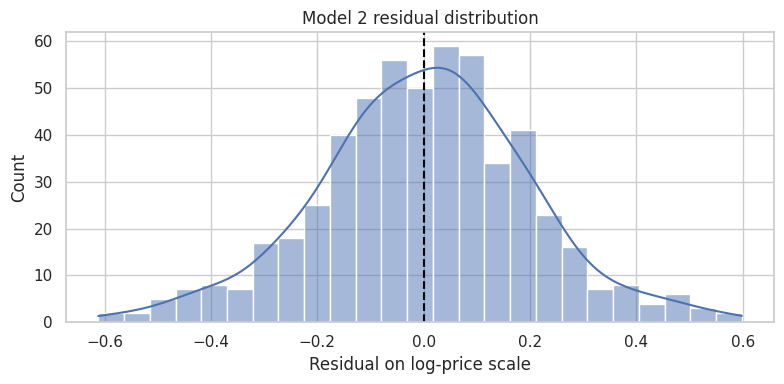

Residual skewness: -0.066
Residual excess kurtosis: 0.395


In [ ]:
# Cell 34: Examine Model 2 residual distribution.
fig, ax = plt.subplots(figsize=(8, 4))

sns.histplot(main_model.resid, bins=25, kde=True, ax=ax)
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Residual on log-price scale")
ax.set_title("Model 2 residual distribution")

plt.tight_layout()
plt.show()

print("Residual skewness:",
      round(stats.skew(main_model.resid, bias=False), 3))
print("Residual excess kurtosis:",
      round(stats.kurtosis(main_model.resid, fisher=True, bias=False), 3))

Re-check VIF

In [ ]:
# Cell 35: VIF for the actual fitted design matrices.
def fitted_model_vif(model):
    X = np.asarray(model.model.exog, dtype=float)
    names = model.model.exog_names

    rows = []

    for i, name in enumerate(names):
        if name not in ["Intercept", "const"]:
            rows.append({
                "term": name,
                "VIF": variance_inflation_factor(X, i)
            })

    return (
        pd.DataFrame(rows)
        .sort_values("VIF", ascending=False)
        .reset_index(drop=True)
    )

print("Model 2 VIF:")
display(fitted_model_vif(model2).round(3))

print("Model 3 VIF, including interaction:")
display(fitted_model_vif(model3).round(3))

Model 2 VIF:


,term,VIF
0,stories,1.471
1,furnishing_furnished,1.454
2,log_area_c,1.385
3,furnishing_semi,1.383
4,bedrooms,1.363
5,basement,1.327
6,bathrooms,1.287
7,airconditioning,1.224
8,guestroom,1.222
9,mainroad,1.192


Model 3 VIF, including interaction:


,term,VIF
0,log_area_c,1.923
1,log_area_c:prefarea,1.652
2,stories,1.475
3,furnishing_furnished,1.454
4,furnishing_semi,1.384
5,bedrooms,1.364
6,basement,1.332
7,bathrooms,1.287
8,mainroad,1.232
9,airconditioning,1.225


Influence diagnostics

In [ ]:
# Cell 36: Calculate influence diagnostics for Model 2.
influence = main_model.get_influence()

n = int(main_model.nobs)
p = len(main_model.params)  # Includes the intercept.

influence_table = pd.DataFrame(
    {
        "cooks_distance": influence.cooks_distance[0],
        "leverage": influence.hat_matrix_diag,
        "studentized_residual": influence.resid_studentized_external
    },
    index=pd.Index(main_rows, name="original_row")
)

# Screening thresholds, not automatic deletion rules.
cook_cutoff = 4 / n
leverage_cutoff = 2 * p / n
studentized_cutoff = 3

influence_table["cook_flag"] = (
    influence_table["cooks_distance"] > cook_cutoff
)
influence_table["leverage_flag"] = (
    influence_table["leverage"] > leverage_cutoff
)
influence_table["residual_flag"] = (
    influence_table["studentized_residual"].abs() > studentized_cutoff
)

influence_table["any_flag"] = influence_table[
    ["cook_flag", "leverage_flag", "residual_flag"]
].any(axis=1)

print(f"Cook's distance screening threshold: {cook_cutoff:.4f}")
print(f"Leverage screening threshold: {leverage_cutoff:.4f}")
print("Absolute studentized-residual threshold:", studentized_cutoff)

display(
    influence_table[
        ["cook_flag", "leverage_flag", "residual_flag", "any_flag"]
    ].sum().rename("Number flagged").to_frame()
)

display(
    influence_table
    .sort_values("cooks_distance", ascending=False)
    .head(10)
)

Cook's distance screening threshold: 0.0073
Leverage screening threshold: 0.0514
Absolute studentized-residual threshold: 3


,Number flagged
cook_flag,34
leverage_flag,27
residual_flag,3
any_flag,54


,cooks_distance,leverage,studentized_residual,cook_flag,leverage_flag,residual_flag,any_flag
original_row,,,,,,,
13,0.032805,0.056467,2.787852,True,True,False,True
20,0.026034,0.051755,2.598085,True,True,False,True
378,0.024544,0.080191,-1.990809,True,True,False,True
499,0.023435,0.060918,-2.257569,True,True,False,True
531,0.023244,0.038898,-2.854564,True,False,False,True
509,0.022463,0.032296,-3.094327,True,False,True,True
220,0.018886,0.041239,-2.491443,True,False,False,True
7,0.017346,0.072515,1.765930,True,True,False,True
464,0.016807,0.049753,-2.126956,True,False,False,True


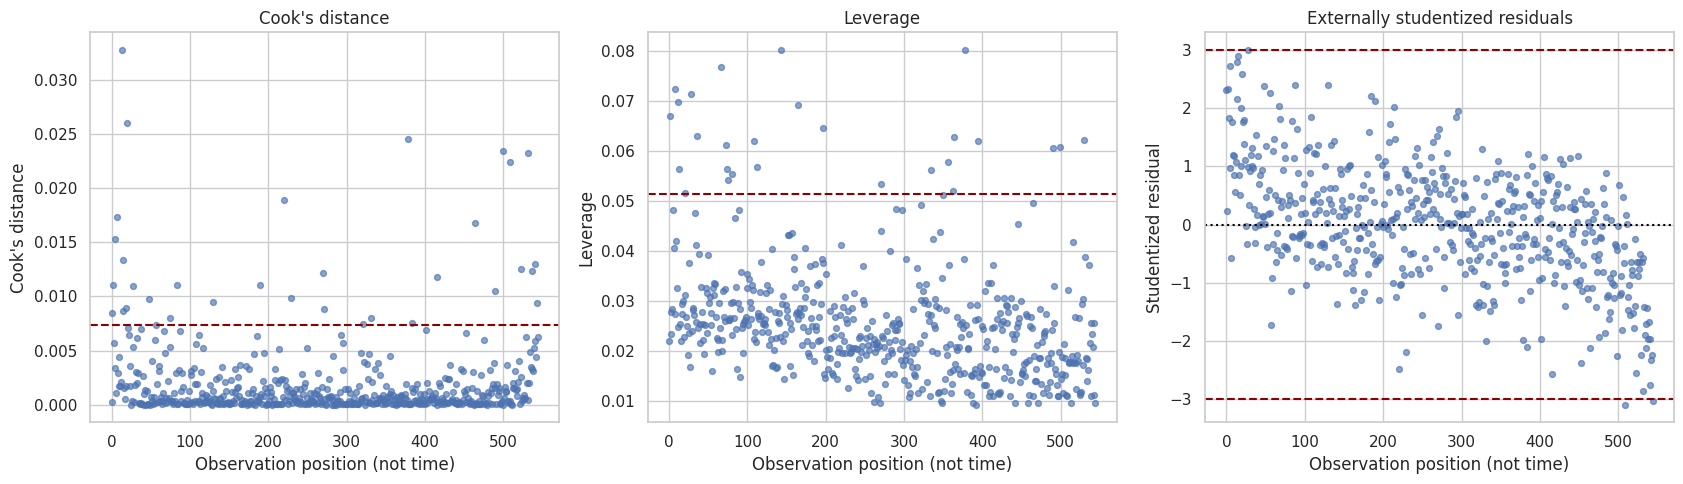

In [ ]:
# Cell 37: Plot the three influence diagnostics.
observation_position = np.arange(n)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(
    observation_position,
    influence_table["cooks_distance"],
    s=18,
    alpha=0.65
)
axes[0].axhline(cook_cutoff, color="darkred", linestyle="--")
axes[0].set_title("Cook's distance")
axes[0].set_ylabel("Cook's distance")

axes[1].scatter(
    observation_position,
    influence_table["leverage"],
    s=18,
    alpha=0.65
)
axes[1].axhline(leverage_cutoff, color="darkred", linestyle="--")
axes[1].set_title("Leverage")
axes[1].set_ylabel("Leverage")

axes[2].scatter(
    observation_position,
    influence_table["studentized_residual"],
    s=18,
    alpha=0.65
)
axes[2].axhline(3, color="darkred", linestyle="--")
axes[2].axhline(-3, color="darkred", linestyle="--")
axes[2].axhline(0, color="black", linestyle=":")
axes[2].set_title("Externally studentized residuals")
axes[2].set_ylabel("Studentized residual")

for ax in axes:
    ax.set_xlabel("Observation position (not time)")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 38: Inspect original records for the most influential homes.
top_rows = (
    influence_table["cooks_distance"]
    .nlargest(10)
    .index
)

records_to_review = df_raw.loc[top_rows].join(
    influence_table[
        ["cooks_distance", "leverage", "studentized_residual"]
    ]
)

display(records_to_review)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,cooks_distance,leverage,studentized_residual
original_row,,,,,,,,,,,,,,,,
13,9240000,3500,4,2,2,yes,no,no,yes,no,2,no,furnished,0.032805,0.056467,2.787852
20,8750000,4320,3,1,2,yes,no,yes,yes,no,2,no,semi-furnished,0.026034,0.051755,2.598085
378,3640000,2275,3,1,3,yes,no,no,yes,yes,0,yes,semi-furnished,0.024544,0.080191,-1.990809
499,2660000,3630,3,3,2,no,yes,no,no,no,0,no,unfurnished,0.023435,0.060918,-2.257569
531,2233000,5300,3,1,1,no,no,no,no,yes,0,yes,unfurnished,0.023244,0.038898,-2.854564
509,2590000,3600,2,2,2,yes,no,yes,no,no,1,no,furnished,0.022463,0.032296,-3.094327
220,4795000,8100,4,1,4,yes,no,yes,no,yes,2,no,semi-furnished,0.018886,0.041239,-2.491443
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished,0.017346,0.072515,1.765930
464,3080000,4500,2,1,2,yes,no,no,yes,no,1,no,semi-furnished,0.016807,0.049753,-2.126956


In [ ]:
# Cell 39: Sensitivity refit excluding Cook's-distance flags only.
sensitivity_model = None
sensitivity_robust = None
sensitivity_comparison = None

excluded_rows = influence_table.index[influence_table["cook_flag"]]

print("Homes omitted in sensitivity analysis:", len(excluded_rows))
print("Original row indexes:", excluded_rows.tolist())

if len(excluded_rows) == 0:
    print("No homes exceed the Cook's-distance screening threshold.")
else:
    sensitivity_data = model_data.drop(index=excluded_rows).copy()

    # Keep the original centering constant: do not recenter this subset.
    sensitivity_spec = smf.ols(
        formula=formula_m2,
        data=sensitivity_data,
        missing="raise"
    )

    X_sensitivity = sensitivity_spec.exog

    if (
        len(sensitivity_data) <= X_sensitivity.shape[1]
        or np.linalg.matrix_rank(X_sensitivity) < X_sensitivity.shape[1]
    ):
        raise ValueError(
            "The reduced sample cannot support the same model. "
            "Review flagged observations individually."
        )

    sensitivity_model = sensitivity_spec.fit()

    sensitivity_robust = sensitivity_model.get_robustcov_results(
        cov_type="HC3",
        use_t=True
    )

    full_ci = np.asarray(main_robust.conf_int())
    sensitivity_ci = np.asarray(sensitivity_robust.conf_int())

    sensitivity_comparison = pd.DataFrame(
        {
            "full_coefficient": np.asarray(main_model.params),
            "sensitivity_coefficient": np.asarray(sensitivity_model.params),
            "full_HC3_CI_lower": full_ci[:, 0],
            "full_HC3_CI_upper": full_ci[:, 1],
            "sensitivity_HC3_CI_lower": sensitivity_ci[:, 0],
            "sensitivity_HC3_CI_upper": sensitivity_ci[:, 1]
        },
        index=main_model.model.exog_names
    )

    sensitivity_comparison["coefficient_change"] = (
        sensitivity_comparison["sensitivity_coefficient"]
        - sensitivity_comparison["full_coefficient"]
    )

    display(sensitivity_comparison.round(4))

Homes omitted in sensitivity analysis: 34
Original row indexes: [0, 2, 4, 7, 13, 14, 15, 18, 20, 27, 48, 57, 74, 84, 130, 189, 220, 229, 270, 271, 321, 331, 378, 383, 415, 464, 490, 499, 509, 523, 531, 536, 540, 543]


,full_coefficient,sensitivity_coefficient,full_HC3_CI_lower,full_HC3_CI_upper,sensitivity_HC3_CI_lower,sensitivity_HC3_CI_upper,coefficient_change
Intercept,14.5120,14.5374,14.4203,14.6037,14.4578,14.6170,0.0254
log_area_c,0.2950,0.2709,0.2438,0.3463,0.2273,0.3145,-0.0241
bedrooms,0.0312,0.0214,0.0031,0.0593,-0.0021,0.0448,-0.0098
bathrooms,0.1605,0.1693,0.1181,0.2029,0.1359,0.2026,0.0088
stories,0.0886,0.0936,0.0660,0.1112,0.0738,0.1134,0.0050
parking_available,0.0797,0.0824,0.0431,0.1163,0.0501,0.1147,0.0027
mainroad,0.1005,0.0808,0.0456,0.1555,0.0337,0.1278,-0.0198
guestroom,0.0507,0.0600,-0.0006,0.1019,0.0176,0.1024,0.0094
basement,0.0963,0.0874,0.0501,0.1426,0.0496,0.1252,-0.0089
hotwaterheating,0.1569,0.1659,0.0502,0.2637,0.0983,0.2336,0.0090


In [ ]:
# Cell 39A: Check whether row order follows price.
print(
    "Price is sorted from highest to lowest:",
    df_raw["price"].is_monotonic_decreasing
)

Price is sorted from highest to lowest: True


,coefficient,HC3_SE,HC3_p,CI_lower,CI_upper
log_area_c,0.2987,0.0263,0.0000,0.2471,0.3503
I(log_area_c ** 2),-0.0483,0.0481,0.3158,-0.1429,0.0462


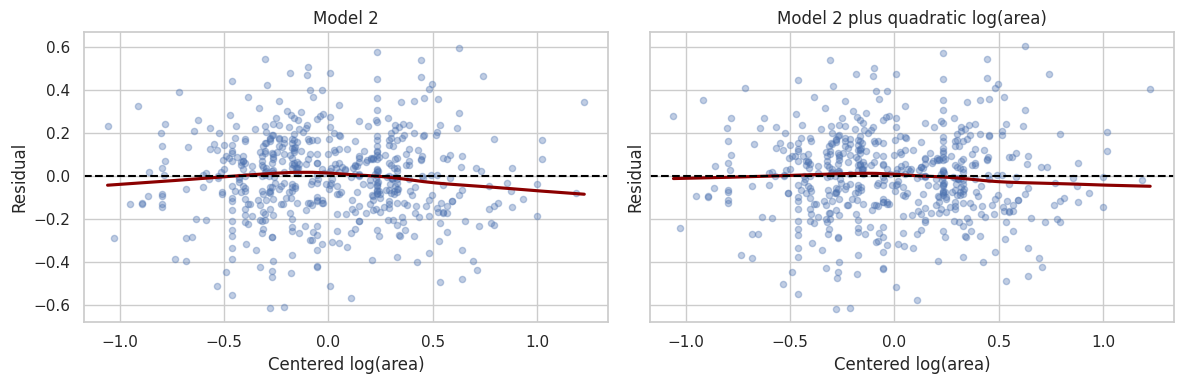

In [ ]:
# Cell 39B: Check remaining curvature in the area association.
model_area_curve = smf.ols(
    formula=formula_m2 + " + I(log_area_c ** 2)",
    data=model_data,
    missing="raise"
).fit()

curve_robust = model_area_curve.get_robustcov_results(
    cov_type="HC3",
    use_t=True
)

curve_ci = np.asarray(curve_robust.conf_int())

curve_table = pd.DataFrame(
    {
        "coefficient": np.asarray(curve_robust.params),
        "HC3_SE": np.asarray(curve_robust.bse),
        "HC3_p": np.asarray(curve_robust.pvalues),
        "CI_lower": curve_ci[:, 0],
        "CI_upper": curve_ci[:, 1]
    },
    index=model_area_curve.model.exog_names
)

display(
    curve_table.loc[
        ["log_area_c", "I(log_area_c ** 2)"]
    ].round(4)
)

# See whether the residual curvature improves.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, model, title in zip(
    axes,
    [model2, model_area_curve],
    ["Model 2", "Model 2 plus quadratic log(area)"]
):
    sns.regplot(
        x=model_data["log_area_c"],
        y=model.resid,
        lowess=True,
        scatter_kws={"alpha": 0.35, "s": 20},
        line_kws={"color": "darkred"},
        ax=ax
    )

    ax.axhline(0, color="black", linestyle="--")
    ax.set_xlabel("Centered log(area)")
    ax.set_ylabel("Residual")
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Compare & interpret

In [ ]:
# Cell 40: Compare models fitted to the same observations and response

models = {
    "Model 1": model1,
    "Model 2": model2,
    "Model 3": model3
}

# Comparisons require the same observations in the same order.
reference_rows = list(model1.model.data.row_labels)

for name, model in models.items():
    assert list(model.model.data.row_labels) == reference_rows, (
        f"{name} uses different observations."
    )
    assert np.array_equal(model.model.endog, model1.model.endog), (
        f"{name} uses a different response."
    )

comparison = pd.DataFrame({
    name: {
        "N": int(model.nobs),
        "Number of slopes": int(model.df_model),
        "R_squared": model.rsquared,
        "Adjusted_R_squared": model.rsquared_adj,
        "AIC": model.aic,
        "BIC_SBC": model.bic
    }
    for name, model in models.items()
}).T

comparison["Delta_AIC"] = comparison["AIC"] - comparison["AIC"].min()
comparison["Delta_BIC"] = comparison["BIC_SBC"] - comparison["BIC_SBC"].min()

display(comparison.round(3))

,N,Number of slopes,R_squared,Adjusted_R_squared,AIC,BIC_SBC,Delta_AIC,Delta_BIC
Model 1,545.0,5.0,0.567,0.563,24.638,50.442,204.214,169.807
Model 2,545.0,13.0,0.711,0.704,-179.576,-119.365,0.000,0.000
Model 3,545.0,14.0,0.711,0.703,-177.650,-113.138,1.926,6.227


In [ ]:
# Cell 41: Classical nested F-tests
# These are shown for completeness.
# Because we found heteroscedasticity, prioritize Cell 42 for inference.

nested_comparisons = [
    ("Model 1 versus Model 2", model1, model2),
    ("Model 2 versus Model 3", model2, model3)
]

classical_results = []

for label, smaller, larger in nested_comparisons:
    f_stat, p_value, df_added = larger.compare_f_test(smaller)

    classical_results.append({
        "Comparison": label,
        "F_statistic": f_stat,
        "p_value": p_value,
        "Added_parameters": int(df_added)
    })

display(pd.DataFrame(classical_results).set_index("Comparison"))

,F_statistic,p_value,Added_parameters
Comparison,,,
Model 1 versus Model 2,33.047898,3.077523e-42,8
Model 2 versus Model 3,0.071923,7.886620e-01,1


In [ ]:
# Cell 42: Joint tests using HC3 robust covariance

robust_models = {
    name: model.get_robustcov_results(cov_type="HC3", use_t=True)
    for name, model in models.items()
}

def robust_joint_test(robust_result, terms, label):
    """Test whether the selected coefficients are jointly zero."""
    names = robust_result.model.exog_names
    restriction_matrix = np.zeros((len(terms), len(names)))

    for row, term in enumerate(terms):
        restriction_matrix[row, names.index(term)] = 1.0

    test = robust_result.f_test(restriction_matrix)

    return {
        "Test": label,
        "HC3_F": np.asarray(test.fvalue).item(),
        "p_value": np.asarray(test.pvalue).item(),
        "Number_of_restrictions": len(terms)
    }

added_m2 = [
    term for term in model2.model.exog_names
    if term not in model1.model.exog_names
]

added_m3 = [
    term for term in model3.model.exog_names
    if term not in model2.model.exog_names
]

robust_tests = pd.DataFrame([
    robust_joint_test(
        robust_models["Model 2"], added_m2,
        "Additional terms in Model 2"
    ),
    robust_joint_test(
        robust_models["Model 3"], added_m3,
        "Area × preferred-area interaction"
    ),
    robust_joint_test(
        robust_models["Model 2"],
        ["furnishing_semi", "furnishing_furnished"],
        "Furnishing status overall"
    )
]).set_index("Test")

display(robust_tests)

,HC3_F,p_value,Number_of_restrictions
Test,,,
Additional terms in Model 2,36.658819,2.899741e-46,8
Area × preferred-area interaction,0.082288,7.743324e-01,1
Furnishing status overall,18.690531,1.431468e-08,2


In [ ]:
# Cell 43: Convert coefficients and HC3 confidence intervals to percentages

final_model = model2
final_robust = robust_models["Model 2"]

names = final_model.model.exog_names
confidence_intervals = np.asarray(final_robust.conf_int())

coefficient_results = pd.DataFrame({
    "Coefficient": np.asarray(final_robust.params),
    "HC3_SE": np.asarray(final_robust.bse),
    "HC3_p": np.asarray(final_robust.pvalues),
    "CI_lower": confidence_intervals[:, 0],
    "CI_upper": confidence_intervals[:, 1]
}, index=names)

contrasts = {
    "log_area_c": "1% more area",
    "bedrooms": "One additional bedroom",
    "bathrooms": "One additional bathroom",
    "stories": "One additional story",
    "parking_available": "Any parking versus none",
    "mainroad": "Main-road access: yes versus no",
    "guestroom": "Guestroom: yes versus no",
    "basement": "Basement: yes versus no",
    "hotwaterheating": "Hot-water heating: yes versus no",
    "airconditioning": "Air conditioning: yes versus no",
    "prefarea": "Preferred area: yes versus no",
    "furnishing_semi": "Semi-furnished versus unfurnished",
    "furnishing_furnished": "Furnished versus unfurnished"
}

effect_rows = []

for term, contrast in contrasts.items():
    row = coefficient_results.loc[term]

    # A 1% area increase changes log(area) by log(1.01).
    # Other contrasts change the relevant predictor by one unit.
    change = np.log(1.01) if term == "log_area_c" else 1.0

    effect_rows.append({
        "Predictor": term,
        "Comparison": contrast,
        "Percent_difference": 100 * np.expm1(row["Coefficient"] * change),
        "CI_lower_percent": 100 * np.expm1(row["CI_lower"] * change),
        "CI_upper_percent": 100 * np.expm1(row["CI_upper"] * change),
        "HC3_p": row["HC3_p"]
    })

effect_table = pd.DataFrame(effect_rows).set_index("Predictor")

display(effect_table.round(4))

,Comparison,Percent_difference,CI_lower_percent,CI_upper_percent,HC3_p
Predictor,,,,,
log_area_c,1% more area,0.2940,0.2429,0.3452,0.0000
bedrooms,One additional bedroom,3.1706,0.3096,6.1133,0.0297
bathrooms,One additional bathroom,17.4104,12.5332,22.4990,0.0000
stories,One additional story,9.2634,6.8212,11.7614,0.0000
parking_available,Any parking versus none,8.2996,4.4079,12.3364,0.0000
mainroad,Main-road access: yes versus no,10.5754,4.6622,16.8227,0.0004
guestroom,Guestroom: yes versus no,5.1962,-0.0598,10.7287,0.0527
basement,Basement: yes versus no,10.1103,5.1328,15.3235,0.0000
hotwaterheating,Hot-water heating: yes versus no,16.9923,5.1505,30.1676,0.0040


In [ ]:
# Cell 44: Direct comparison between the two non-reference furnishing levels

furnishing_test = final_robust.t_test(
    "furnishing_furnished - furnishing_semi = 0"
)

difference = np.asarray(furnishing_test.effect).item()
lower, upper = np.asarray(furnishing_test.conf_int()).reshape(-1)

furnishing_comparison = pd.DataFrame({
    "Comparison": ["Furnished versus semi-furnished"],
    "Percent_difference": [100 * np.expm1(difference)],
    "CI_lower_percent": [100 * np.expm1(lower)],
    "CI_upper_percent": [100 * np.expm1(upper)],
    "HC3_p": [np.asarray(furnishing_test.pvalue).item()]
})

display(furnishing_comparison.round(4))

,Comparison,Percent_difference,CI_lower_percent,CI_upper_percent,HC3_p
0,Furnished versus semi-furnished,-1.4078,-5.5173,2.8804,0.5133
